# Forecasting SPY volatility: naive vs HAR vs GARCH vs XGBoost

**Question:** Can a machine-learning model forecast next week's SPY volatility better than the classic econometric models, out of sample?

**Setup**
- **Target:** realized variance over the next 5 trading days, $RV_{t+1:t+5} = \sum_{i=1}^{5} r_{t+i}^2$ (daily log returns, in %).
- **Models:** each forecasts that target using only information available at the close of day $t$.
  1. **Naive:** the last 22 days' average squared return × 5.
  2. **HAR-RV** (Corsi, 2009): a linear regression on daily, weekly and monthly realized variance. This is the standard benchmark in the volatility literature, and the one ML actually needs to beat.
  3. **GJR-GARCH(1,1)** with Student-t errors. The GJR term lets negative returns raise volatility more than positive ones (the "leverage effect").
  4. **XGBoost** on lagged volatility features, past returns and the VIX.
- **Out-of-sample protocol:** walk-forward. Every model is refit on an expanding window using only past data, and forecasts start in `TEST_START`. The test period is never used for fitting or tuning.
- **Scoring:** MSE and **QLIKE**. QLIKE is the preferred loss for volatility because it stays reliable when the "true" variance is measured with noise (Patton, 2011). A Diebold-Mariano test checks whether the differences are statistically significant.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from arch import arch_model
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (12, 4.5)

# ---- Configuration ----
TICKER = "SPY"
VIX_TICKER = "^VIX"
START = "2000-01-01"
TEST_START = "2015-01-01"   # forecasts are scored from here on
HORIZON = 5                 # forecast the next 5 trading days
GARCH_REFIT_EVERY = 21      # trading days between GARCH refits
ML_REFIT_EVERY = 63         # trading days between HAR / XGBoost refits
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

## 1. Data
Prices are downloaded once with `yfinance` and cached to `data/` as parquet files, so reruns are instant and use exactly the same data. Delete the folder to refresh.

c:\Users\conno\miniforge3\envs\dev\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\conno\miniforge3\envs\dev\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
c:\Users\conno\miniforge3\envs\dev\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.sort_index(inplac

6,761 daily returns, 2000-01-04 to 2026-11-19


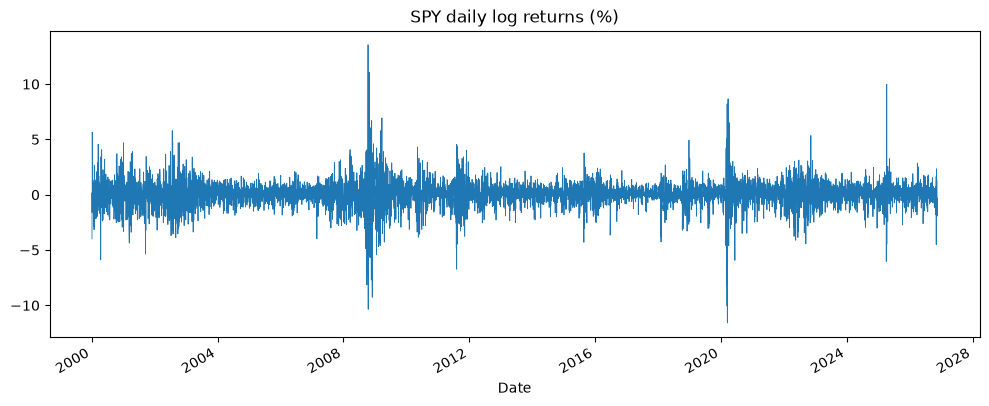

In [2]:
def load_close(ticker: str) -> pd.Series:
    path = DATA_DIR / f"{ticker.replace('^', '')}.parquet"
    if path.exists():
        return pd.read_parquet(path)["close"]
    import yfinance as yf
    df = yf.download(ticker, start=START, auto_adjust=True, progress=False)
    if df.empty:
        raise RuntimeError(f"No data downloaded for {ticker}; check your connection.")
    close = df["Close"].squeeze().rename("close")   # newer yfinance returns multi-level columns
    close.index = pd.to_datetime(close.index).tz_localize(None)
    close.to_frame().to_parquet(path)
    return close

spy = load_close(TICKER)
vix = load_close(VIX_TICKER)

r = (100 * np.log(spy).diff()).dropna().rename("r")        # daily log return, %
vix = vix.reindex(r.index).ffill()

print(f"{len(r):,} daily returns, {r.index[0].date()} to {r.index[-1].date()}")
r.plot(title=f"{TICKER} daily log returns (%)", lw=0.6);

## 2. Target and features
Everything in row $t$ is known at the close of day $t$, **except** the target, which looks 5 days ahead.

The features are built in logs because volatility is right-skewed and roughly log-normal, which tree models and regressions both handle better. The negative-return features capture the leverage effect. VIX is the market's own forward-looking volatility estimate, converted here to the same units as the target.

In [3]:
r2 = r ** 2
df = pd.DataFrame({"r": r})

# Target: realized variance over t+1 .. t+HORIZON
df["y"] = r2.rolling(HORIZON).sum().shift(-HORIZON)

# HAR components (average daily variance over 1, 5, 22 days)
df["rv_d"] = r2
df["rv_w"] = r2.rolling(5).mean()
df["rv_m"] = r2.rolling(22).mean()

# Extra features for XGBoost
df["rv_q"] = r2.rolling(63).mean()
df["ret_5"] = r.rolling(5).sum()
df["ret_22"] = r.rolling(22).sum()
df["neg_rv_w"] = (r.clip(upper=0) ** 2).rolling(5).mean()      # downside variance
df["vix_var"] = vix ** 2 / 252 * HORIZON                        # VIX-implied 5-day variance, %^2

eps = 1e-4
for c in ["rv_d", "rv_w", "rv_m", "rv_q", "neg_rv_w", "vix_var"]:
    df[f"log_{c}"] = np.log(df[c] + eps)

XGB_FEATURES = ["log_rv_d", "log_rv_w", "log_rv_m", "log_rv_q", "log_neg_rv_w",
                "log_vix_var", "ret_5", "ret_22"]
HAR_FEATURES = ["rv_d", "rv_w", "rv_m"]

df = df.dropna(subset=HAR_FEATURES + XGB_FEATURES)
test_idx = df.loc[TEST_START:].dropna(subset=["y"]).index
print(f"Test period: {test_idx[0].date()} to {test_idx[-1].date()}  ({len(test_idx):,} forecasts)")

Test period: 2015-01-02 to 2026-11-12  (2,984 forecasts)


## 3. Walk-forward engine
**The lookahead trap:** on a refit date $d$, the targets for the last 5 days before $d$ aren't known yet, because they depend on returns after $d$. Training on them would leak the future. `walk_forward` drops ("purges") those rows. Forgetting this is one of the most common bugs in published-looking backtests.

In [4]:
def walk_forward(fit_predict, features, refit_every):
    # Refit on an expanding window every `refit_every` days; forecast until the next refit.
    preds = pd.Series(index=test_idx, dtype=float)
    for start in range(0, len(test_idx), refit_every):
        block = test_idx[start:start + refit_every]
        refit_date = block[0]
        train = df.loc[:refit_date].iloc[:-1]           # strictly before the refit date
        train = train.iloc[:-HORIZON].dropna(subset=["y"])  # purge targets that overlap the future
        preds.loc[block] = fit_predict(train[features], train["y"], df.loc[block, features])
    return preds

forecasts = pd.DataFrame(index=test_idx)

## 4. Models
### 4a. Naive: recent average variance

In [5]:
forecasts["Naive"] = df.loc[test_idx, "rv_m"] * HORIZON

### 4b. HAR-RV

In [6]:
def har_fit_predict(X, y, X_new):
    model = sm.OLS(y, sm.add_constant(X)).fit()
    pred = model.predict(sm.add_constant(X_new, has_constant="add"))
    return np.maximum(pred, 1e-3)          # linear models can go negative; variance can't

forecasts["HAR"] = walk_forward(har_fit_predict, HAR_FEATURES, ML_REFIT_EVERY)

### 4c. GJR-GARCH(1,1), Student-t
`arch` handles walk-forward natively. `fit(last_obs=d)` estimates the parameters on data before `d`, and `forecast(start=d)` then produces a forecast at each later date using only the returns up to that date. Summing the 1- to 5-day-ahead variances gives the 5-day forecast.

In [7]:
am = arch_model(r, mean="Constant", vol="GARCH", p=1, o=1, q=1, dist="t", rescale=False)
garch = pd.Series(index=test_idx, dtype=float)

for start in range(0, len(test_idx), GARCH_REFIT_EVERY):
    block = test_idx[start:start + GARCH_REFIT_EVERY]
    res = am.fit(last_obs=block[0], disp="off")
    fc = res.forecast(horizon=HORIZON, start=block[0], reindex=False)
    garch.loc[block] = fc.variance.loc[block].sum(axis=1)

forecasts["GARCH"] = garch
print(res.params.round(4))   # latest fitted parameters

mu          0.0600
omega       0.0193
alpha[1]    0.0000
gamma[1]    0.2137
beta[1]     0.8762
nu          6.6666
Name: params, dtype: float64


### 4d. XGBoost
The model is trained on **log** variance and the forecast is mapped back with $\exp(\hat{y})$. That would systematically under-forecast (Jensen's inequality), so the prediction is scaled by the average of $\exp(\text{residual})$ on the training set (Duan's smearing correction).

The hyperparameters are deliberately conservative and **were not tuned on the test period**. Tuning them properly, with validation inside each training window, is one of the extensions at the end.

In [8]:
def xgb_fit_predict(X, y, X_new):
    model = XGBRegressor(n_estimators=400, max_depth=3, learning_rate=0.03,
                         subsample=0.8, colsample_bytree=0.8, min_child_weight=20,
                         random_state=0, n_jobs=-1)
    log_y = np.log(y + 1e-4)
    model.fit(X, log_y)
    smear = np.mean(np.exp(log_y - model.predict(X)))
    xgb_fit_predict.last_model = model
    return np.exp(model.predict(X_new)) * smear

forecasts["XGBoost"] = walk_forward(xgb_fit_predict, XGB_FEATURES, ML_REFIT_EVERY)

## 5. Evaluation
- **MSE** is dominated by a few crisis weeks. It's useful to know, but it's noisy.
- **QLIKE** $= \frac{y}{f} - \ln\frac{y}{f} - 1$ penalizes under-forecasting more than over-forecasting, which suits risk management. Lower is better for both.
- **Mincer-Zarnowitz $R^2$:** how much of the variation in realized variance each forecast explains.
- **Diebold-Mariano:** is the gap in losses between two models statistically real? The overlapping 5-day targets make losses autocorrelated, so it uses Newey-West (HAC) errors.

In [9]:
y = df.loc[test_idx, "y"].clip(lower=1e-6)

def qlike(y, f):
    return y / f - np.log(y / f) - 1

def mz_r2(y, f):
    return sm.OLS(y, sm.add_constant(f)).fit().rsquared

def dm_test(loss_a, loss_b):
    # Positive t-stat => model A has higher loss (B is better)
    d = (loss_a - loss_b).dropna()
    res = sm.OLS(d, np.ones(len(d))).fit(cov_type="HAC", cov_kwds={"maxlags": HORIZON})
    return res.tvalues.iloc[0], res.pvalues.iloc[0]

losses_q = forecasts.apply(lambda f: qlike(y, f))
losses_mse = forecasts.apply(lambda f: (y - f) ** 2)

summary = pd.DataFrame({
    "QLIKE": losses_q.mean(),
    "QLIKE vs Naive": losses_q.mean() / losses_q["Naive"].mean(),
    "MSE": losses_mse.mean(),
    "MSE vs Naive": losses_mse.mean() / losses_mse["Naive"].mean(),
    "MZ R2": forecasts.apply(lambda f: mz_r2(y, f)),
}).sort_values("QLIKE")
display(summary.round(3))

rows = []
for a in forecasts:
    for b in forecasts:
        if a < b:
            t, p = dm_test(losses_q[a], losses_q[b])
            better = b if t > 0 else a
            rows.append({"A": a, "B": b, "DM t-stat": round(t, 2), "p-value": round(p, 3),
                         "better (QLIKE)": better if p < 0.05 else "no significant difference"})
display(pd.DataFrame(rows))

,QLIKE,QLIKE vs Naive,MSE,MSE vs Naive,MZ R2
XGBoost,0.416,0.644,175.635,0.589,0.453
GARCH,0.479,0.743,216.200,0.725,0.386
HAR,0.491,0.761,219.274,0.735,0.320
Naive,0.645,1.000,298.230,1.000,0.181


,A,B,DM t-stat,p-value,better (QLIKE)
0,Naive,XGBoost,4.96,0.000,XGBoost
1,HAR,Naive,-3.57,0.000,HAR
2,HAR,XGBoost,2.98,0.003,XGBoost
3,GARCH,Naive,-4.34,0.000,GARCH
4,GARCH,HAR,-0.51,0.613,no significant difference
5,GARCH,XGBoost,2.28,0.023,XGBoost


## 6. What the forecasts look like
Shown as annualized volatility (%), which is easier to read than 5-day variance.

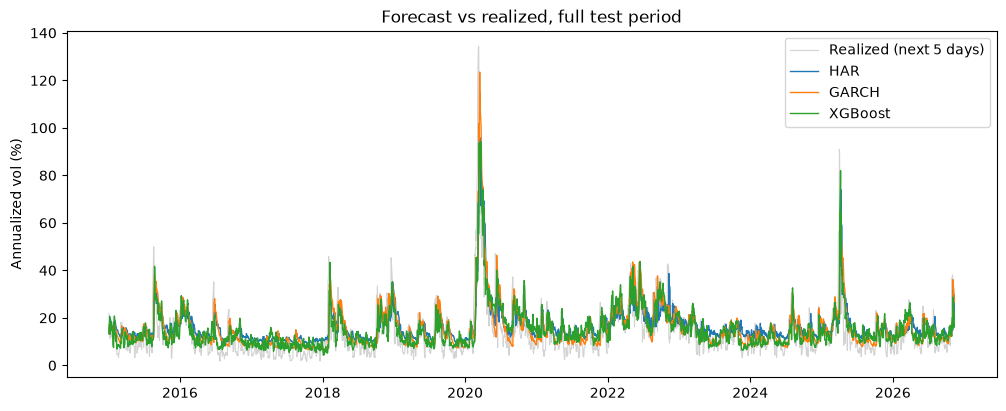

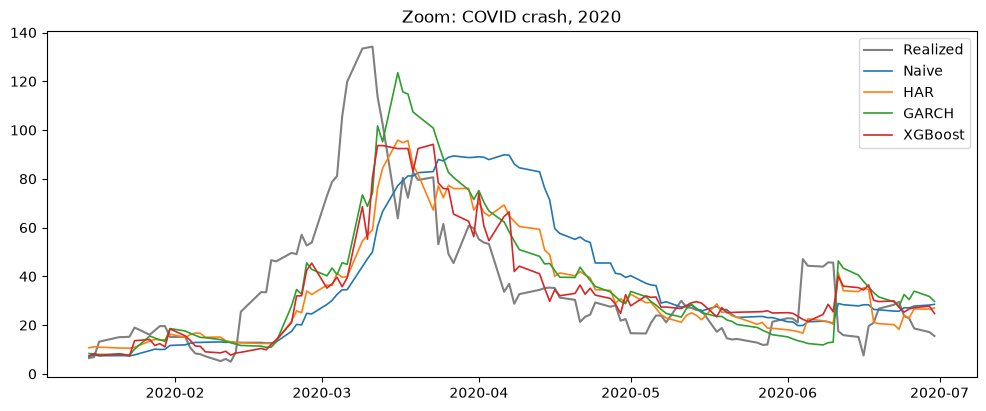

In [10]:
to_ann_vol = lambda v: np.sqrt(v * 252 / HORIZON)

fig, ax = plt.subplots()
ax.plot(to_ann_vol(y), color="lightgray", lw=0.8, label="Realized (next 5 days)")
for col in ["HAR", "GARCH", "XGBoost"]:
    ax.plot(to_ann_vol(forecasts[col]), lw=1, label=col)
ax.set_ylabel("Annualized vol (%)"); ax.set_title("Forecast vs realized, full test period")
ax.legend(); plt.show()

window = slice("2020-01-15", "2020-06-30")
fig, ax = plt.subplots()
ax.plot(to_ann_vol(y.loc[window]), color="gray", lw=1.5, label="Realized")
for col in forecasts:
    ax.plot(to_ann_vol(forecasts.loc[window, col]), lw=1.2, label=col)
ax.set_title("Zoom: COVID crash, 2020"); ax.legend(); plt.show()

**When does XGBoost win or lose?** The chart below shows the cumulative QLIKE advantage of XGBoost over GARCH. A rising line means XGBoost is winning. Jumps usually line up with regime changes, which is where models differ most.

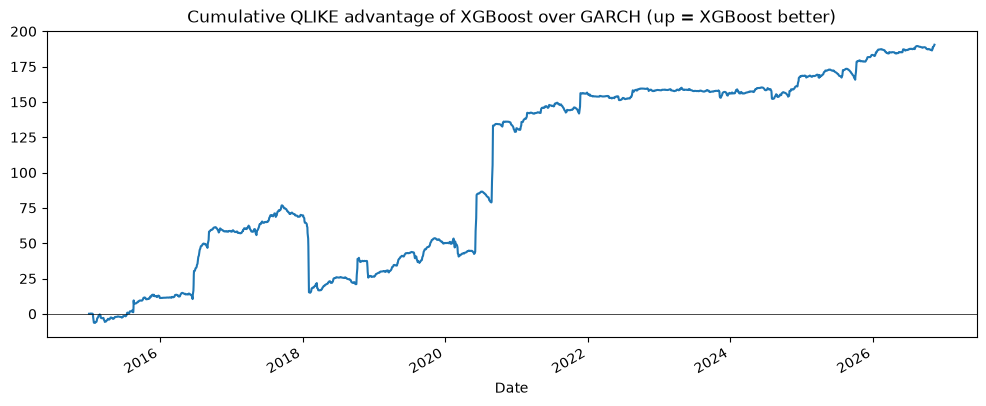

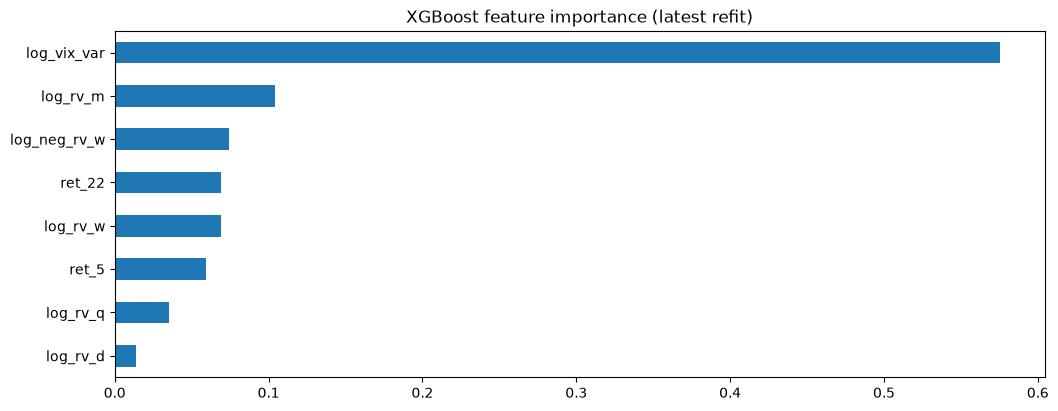

In [11]:
cum = (losses_q["GARCH"] - losses_q["XGBoost"]).cumsum()
ax = cum.plot(title="Cumulative QLIKE advantage of XGBoost over GARCH (up = XGBoost better)")
ax.axhline(0, color="k", lw=0.5); plt.show()

importance = pd.Series(xgb_fit_predict.last_model.feature_importances_, index=XGB_FEATURES)
importance.sort_values().plot.barh(title="XGBoost feature importance (latest refit)"); plt.show()

## 7. Findings

- The most powerful model of all the models tested was XGBoost, which beat out Naive (not surprising) as well as HAR and GARCH (more surprising). In the photos Forecast vs Realized, Zoom Covid Crash around 2020, and Cumulative QLike Advantage of XGBoost over GARCH, XGBoost was shown to be incredibly accurate especially over HAR. From 2021 on, the cumulative qlike advantage was over 125 which is significant from years prior. Around the Covid Crash, the only other model that performed that well was GARCH which had a hiccup around March to April
- A good amount but not a significant amount of the edge in XGBoost came from VIX. You can see in the tables that now there is no significant difference between HAR AND XGBoost, but HAR with VIX and XGBoost are significantly different with XGBoost performing better. In the plot comparing XGBoost, XGBoost without VIX , and HAR and VIX, the QLike Advantage is astronomical. In the Zoom Covid Crash, the only major difference between XGBoost and XGBoost without Vix is really around March and April, but it isn't that large of a difference at all.
- It is important to note that GARCH responded the fastest to the March explosion in the Zoom Covid Crash plots. Followed by Garch for explosion reaction was XGBoost (Without VIX being the slowest in the ablation research section down below) but GARCH overshot the down range section towards the end of the plot here above.
- Conclusion: The most powerful of all models, even excluding some features was XGBoost, which beat out the traditional HAR model. Even though it was slower than GARCH on the come up in March 2020, XGBoost forecasted volume than all other models.

## 8. Extensions (turning this into a month-plus project as of 11/19/2026)
1. **Better realized variance.** Daily squared returns are a very noisy measure of the truth. Intraday 5-minute realized variance would sharpen every result.
2. **Proper tuning.** Use time-series cross-validation *inside* each training window for the XGBoost hyperparameters.
3. **More assets:** QQQ, IWM, TLT, GLD, sector ETFs. Is the ranking of the models stable?
4. **Ablations:** drop one feature group at a time to measure what each contributes.
5. **More features:** VIX term structure (`^VIX3M`), credit spreads and yields from FRED, calendar effects such as FOMC days.
6. **Economic value:** use each forecast to run a volatility-targeting strategy, then compare Sharpe ratios and drawdowns after costs. That's the question a portfolio manager actually cares about.



Conclusions on extensions: Better realized variances , proper tuning, and ablations with including ARIMA and LSTM to visit old Senior Project is how this project will be extended.

## 9. Ablation: how much of XGBoost's edge comes from the VIX?
Two extra models answer two different questions:

1. **XGBoost (no VIX):** the same model and settings with `log_vix_var` removed. *How much does XGBoost lose without the VIX?*
2. **HAR + VIX:** the plain linear HAR regression with the VIX-implied variance added as a fourth input. *Is the edge from the VIX information itself, or from XGBoost's flexibility?*

How to read the results:
- If XGBoost without the VIX falls back to GARCH/HAR levels **and** HAR + VIX catches up with XGBoost, the edge is the VIX, not the machine learning.
- If XGBoost without the VIX still wins, the model is extracting something from the historical features alone.
- If HAR + VIX improves but still trails XGBoost, both matter: the VIX helps, and the nonlinearity adds something on top.

The original `forecasts` table is left unchanged. These results go in a separate `ablation` table.

In [12]:
XGB_FEATURES_NO_VIX = [f for f in XGB_FEATURES if f != "log_vix_var"]
HAR_VIX_FEATURES = HAR_FEATURES + ["vix_var"]
print("XGBoost (no VIX) features:", XGB_FEATURES_NO_VIX)
print("HAR + VIX features:       ", HAR_VIX_FEATURES)

ablation = forecasts.copy()
ablation["XGBoost (no VIX)"] = walk_forward(xgb_fit_predict, XGB_FEATURES_NO_VIX, ML_REFIT_EVERY)
no_vix_model = xgb_fit_predict.last_model          # keep it for the importance chart below
ablation["HAR + VIX"] = walk_forward(har_fit_predict, HAR_VIX_FEATURES, ML_REFIT_EVERY)

XGBoost (no VIX) features: ['log_rv_d', 'log_rv_w', 'log_rv_m', 'log_rv_q', 'log_neg_rv_w', 'ret_5', 'ret_22']
HAR + VIX features:        ['rv_d', 'rv_w', 'rv_m', 'vix_var']


In [13]:
abl_q = ablation.apply(lambda f: qlike(y, f))
abl_mse = ablation.apply(lambda f: (y - f) ** 2)

abl_summary = pd.DataFrame({
    "QLIKE": abl_q.mean(),
    "QLIKE vs Naive": abl_q.mean() / abl_q["Naive"].mean(),
    "MSE": abl_mse.mean(),
    "MSE vs Naive": abl_mse.mean() / abl_mse["Naive"].mean(),
    "MZ R2": ablation.apply(lambda f: mz_r2(y, f)),
}).sort_values("QLIKE")
display(abl_summary.round(3))

# Head-to-head Diebold-Mariano tests on QLIKE (positive t-stat => B is better)
pairs = [("XGBoost (no VIX)", "XGBoost"),
         ("GARCH", "XGBoost (no VIX)"),
         ("HAR", "XGBoost (no VIX)"),
         ("HAR", "HAR + VIX"),
         ("GARCH", "HAR + VIX"),
         ("HAR + VIX", "XGBoost")]
rows = []
for a, b in pairs:
    t, p = dm_test(abl_q[a], abl_q[b])
    better = b if t > 0 else a
    rows.append({"A": a, "B": b, "DM t-stat": round(t, 2), "p-value": round(p, 3),
                 "better (QLIKE)": better if p < 0.05 else "no significant difference"})
display(pd.DataFrame(rows))

# What share of XGBoost's QLIKE advantage disappears without the VIX?
for bench in ["GARCH", "HAR"]:
    full_edge = abl_q[bench].mean() - abl_q["XGBoost"].mean()
    no_vix_edge = abl_q[bench].mean() - abl_q["XGBoost (no VIX)"].mean()
    if full_edge <= 0:
        print(f"vs {bench:5s}: XGBoost has no edge over {bench} to explain")
        continue
    share = 1 - no_vix_edge / full_edge
    print(f"vs {bench:5s}: edge with VIX {full_edge:.3f}, without {no_vix_edge:.3f}  "
          f"->  {share:.0%} of the edge comes from the VIX")

,QLIKE,QLIKE vs Naive,MSE,MSE vs Naive,MZ R2
XGBoost,0.416,0.644,175.635,0.589,0.453
GARCH,0.479,0.743,216.200,0.725,0.386
HAR,0.491,0.761,219.274,0.735,0.320
XGBoost (no VIX),0.491,0.761,201.704,0.676,0.382
Naive,0.645,1.000,298.230,1.000,0.181
HAR + VIX,95.425,147.857,192.201,0.644,0.403


,A,B,DM t-stat,p-value,better (QLIKE)
0,XGBoost (no VIX),XGBoost,3.94,0.000,XGBoost
1,GARCH,XGBoost (no VIX),-0.40,0.691,no significant difference
2,HAR,XGBoost (no VIX),-0.01,0.996,no significant difference
3,HAR,HAR + VIX,-5.90,0.000,HAR
4,GARCH,HAR + VIX,-5.90,0.000,GARCH
5,HAR + VIX,XGBoost,5.90,0.000,XGBoost


vs GARCH: edge with VIX 0.064, without -0.012  ->  118% of the edge comes from the VIX
vs HAR  : edge with VIX 0.075, without -0.000  ->  100% of the edge comes from the VIX


### Where the VIX matters
Both versions of XGBoost measured against GARCH over time. Watch where the two lines **separate**. Those are the periods when the VIX carried information that past returns didn't, typically right before or at the start of a volatility spike.

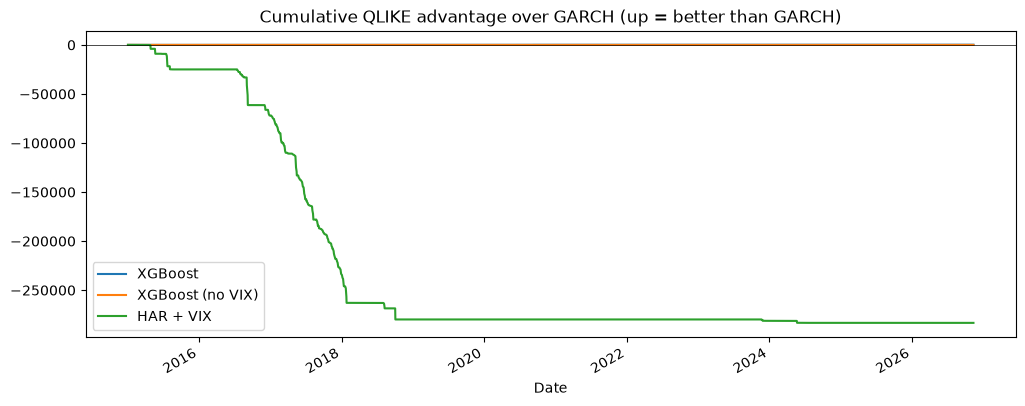

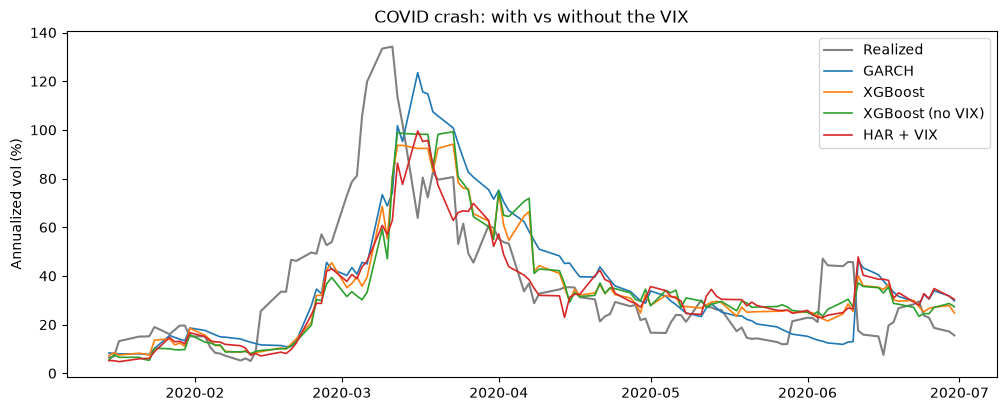

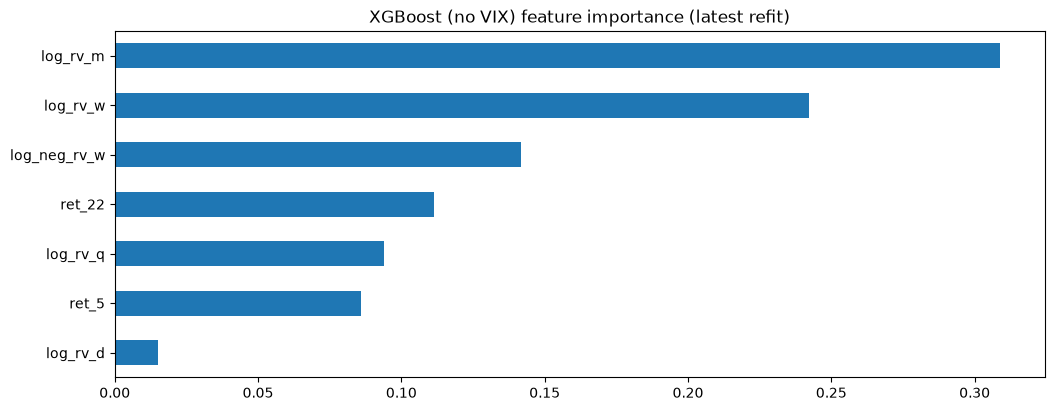

In [14]:
fig, ax = plt.subplots()
for col in ["XGBoost", "XGBoost (no VIX)", "HAR + VIX"]:
    (abl_q["GARCH"] - abl_q[col]).cumsum().plot(ax=ax, label=col)
ax.axhline(0, color="k", lw=0.5)
ax.set_title("Cumulative QLIKE advantage over GARCH (up = better than GARCH)")
ax.legend(); plt.show()

window = slice("2020-01-15", "2020-06-30")
fig, ax = plt.subplots()
ax.plot(to_ann_vol(y.loc[window]), color="gray", lw=1.5, label="Realized")
for col in ["GARCH", "XGBoost", "XGBoost (no VIX)", "HAR + VIX"]:
    ax.plot(to_ann_vol(ablation.loc[window, col]), lw=1.2, label=col)
ax.set_ylabel("Annualized vol (%)"); ax.set_title("COVID crash: with vs without the VIX")
ax.legend(); plt.show()

pd.Series(no_vix_model.feature_importances_, index=XGB_FEATURES_NO_VIX).sort_values().plot.barh(
    title="XGBoost (no VIX) feature importance (latest refit)"); plt.show()